<a href="https://colab.research.google.com/github/GabyPaolaING/Machine-Learning/blob/main/RedNeuronal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ejecutando en: cuda


100%|██████████| 170M/170M [21:00<00:00, 135kB/s]


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 129MB/s]


Epoch [1/20], Train Loss: 1.7409, Train Acc: 0.3487
Test Loss: 1.3356, Test Acc: 0.4993, Precision: 0.5045, Recall: 0.5003, F2 Score: 0.4864
Epoch [2/20], Train Loss: 1.3132, Train Acc: 0.5276
Test Loss: 1.1361, Test Acc: 0.5944, Precision: 0.5985, Recall: 0.5943, F2 Score: 0.5838
Epoch [3/20], Train Loss: 1.1589, Train Acc: 0.5874
Test Loss: 1.0350, Test Acc: 0.6392, Precision: 0.6511, Recall: 0.6403, F2 Score: 0.6365
Epoch [4/20], Train Loss: 1.0639, Train Acc: 0.6274
Test Loss: 0.9192, Test Acc: 0.6767, Precision: 0.6791, Recall: 0.6778, F2 Score: 0.6744
Epoch [5/20], Train Loss: 0.9792, Train Acc: 0.6607
Test Loss: 0.9722, Test Acc: 0.6615, Precision: 0.6799, Recall: 0.6645, F2 Score: 0.6546
Epoch [6/20], Train Loss: 0.9154, Train Acc: 0.6801
Test Loss: 0.8734, Test Acc: 0.7006, Precision: 0.7082, Recall: 0.7019, F2 Score: 0.7007
Epoch [7/20], Train Loss: 0.8707, Train Acc: 0.6981
Test Loss: 0.8321, Test Acc: 0.7162, Precision: 0.7138, Recall: 0.7169, F2 Score: 0.7139
Epoch [8/20],

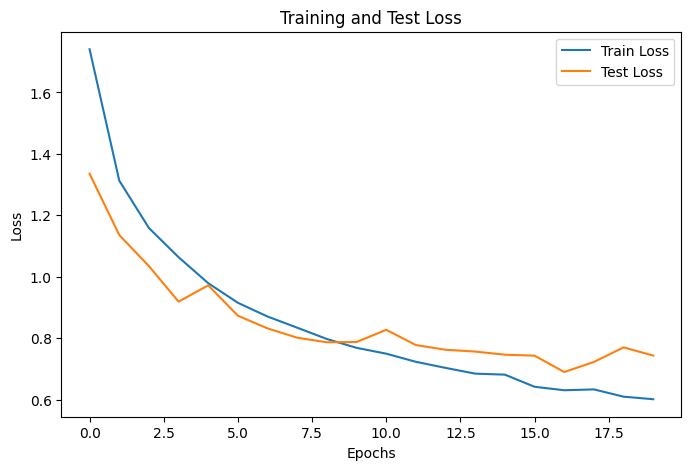

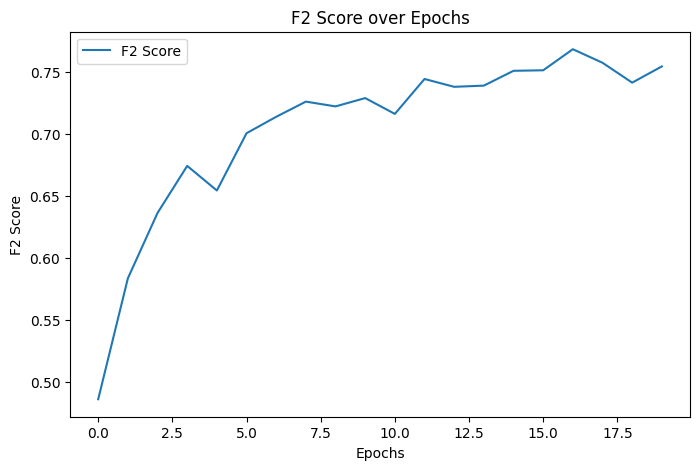

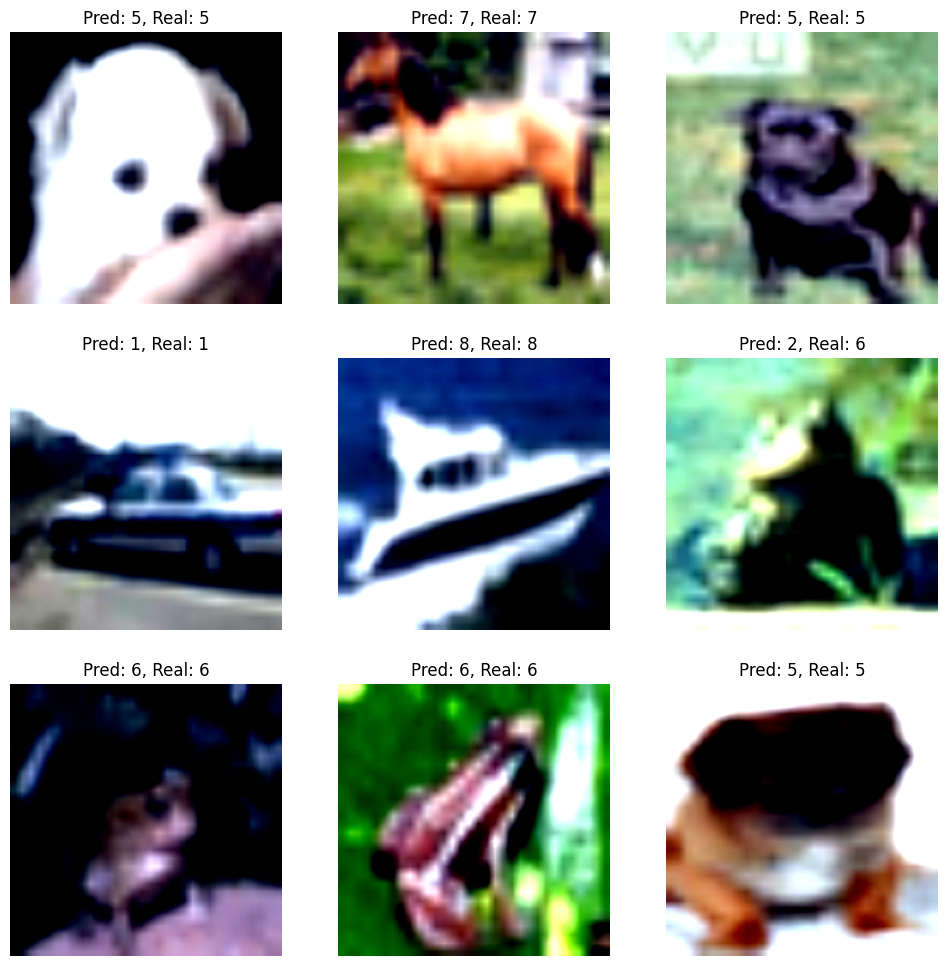

In [4]:
from pathlib import Path
from urllib.error import URLError

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from sklearn.metrics import f1_score, precision_score, recall_score, fbeta_score

# Verificar si la GPU de Colab está activa
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Ejecutando en: {device}")

# Hiperparámetros
batch_size = 64
learning_rate = 0.001
num_epochs = 20

# Transformaciones y carga de datos
transform = transforms.Compose([
    transforms.Resize((227, 227)),  # Cambiar el tamaño de la imagen a 227x227
    transforms.ToTensor(),          # Convertir la imagen en un tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalización de ImageNet
])

# Cargar CIFAR-10 en el almacenamiento temporal de Colab
data_dir = Path('./data')
try:
    dataset = datasets.CIFAR10(
        root=str(data_dir), train=True, download=True, transform=transform
    )
except (URLError, TimeoutError) as error:
    raise RuntimeError(
        f"No se pudo descargar CIFAR-10. Comprueba la conexión o descarga "
        f"manualmente https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz "
        f"y guarda cifar-10-python.tar.gz en {data_dir}. Luego vuelve a ejecutar "
        "el script."
    ) from error

# Dividir el dataset en 80% para entrenamiento y 20% para prueba
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

# Crear los DataLoaders (num_workers=2 acelera la carga en Colab)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# Cargar AlexNet preentrenada
model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)

# Modificar la capa final para clasificar 10 clases
model.classifier[6] = nn.Linear(4096, 10)

# Mover el modelo al dispositivo (GPU)
model = model.to(device)

# Inicializar función de pérdida y optimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Listas para almacenar las pérdidas y F2 score
train_losses = []
test_losses = []
f2_scores = []

# Bucle de entrenamiento
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass y optimización
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total
    train_losses.append(train_loss)
    print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.4f}")

    # Evaluación en el conjunto de prueba después de cada epoch
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())

    test_accuracy = correct / total
    precision = precision_score(all_labels, all_predictions, average='macro', zero_division=0)
    recall = recall_score(all_labels, all_predictions, average='macro', zero_division=0)
    test_f2_score = fbeta_score(all_labels, all_predictions, average='macro', beta=2, zero_division=0)

    test_losses.append(test_loss / len(test_loader))
    f2_scores.append(test_f2_score)

    print(f"Test Loss: {test_loss / len(test_loader):.4f}, Test Acc: {test_accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F2 Score: {test_f2_score:.4f}")

# Guardar el modelo en el panel de archivos de Colab
torch.save(model.state_dict(), 'alexnet_cifar10_pretrained.pth')

# Graficar las pérdidas de entrenamiento y prueba
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Test Loss')
plt.show()

# Graficar el F2 score
plt.figure(figsize=(8, 5))
plt.plot(f2_scores, label='F2 Score')
plt.xlabel('Epochs')
plt.ylabel('F2 Score')
plt.legend()
plt.title('F2 Score over Epochs')
plt.show()

# Mostrar imágenes clasificadas del conjunto de prueba
model.eval()
fig = plt.figure(figsize=(12, 12))
with torch.no_grad():
    for i, (images, labels) in enumerate(test_loader):
        if i == 1:
            break
        outputs = model(images.to(device))
        _, predicted = torch.max(outputs, 1)

        for j in range(min(9, images.size(0))):
            ax = fig.add_subplot(3, 3, j + 1)
            img = images[j].cpu().numpy().transpose((1, 2, 0))
            img = np.clip(img * 0.5 + 0.5, 0, 1)  # Clip evita avisos de rango RGB en Colab
            ax.imshow(img)
            ax.set_title(f'Pred: {predicted[j].item()}, Real: {labels[j].item()}')
            ax.axis('off')

plt.show()

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 190MB/s]


Entrenando en dispositivo: cuda
Epoch [1/20] (LR: 0.000497) | Train Loss: 0.4998, Train Acc: 0.8328 | Test Loss: 0.4043, Test Acc: 86.10%, Precision: 0.8639, Recall: 0.8603, F2: 0.8594
Epoch [2/20] (LR: 0.000488) | Train Loss: 0.3071, Train Acc: 0.8962 | Test Loss: 0.3008, Test Acc: 90.10%, Precision: 0.9055, Recall: 0.9008, F2: 0.9005
Epoch [3/20] (LR: 0.000473) | Train Loss: 0.2470, Train Acc: 0.9163 | Test Loss: 0.2520, Test Acc: 91.62%, Precision: 0.9174, Recall: 0.9164, F2: 0.9161
Epoch [4/20] (LR: 0.000452) | Train Loss: 0.2017, Train Acc: 0.9307 | Test Loss: 0.2071, Test Acc: 92.91%, Precision: 0.9292, Recall: 0.9286, F2: 0.9286
Epoch [5/20] (LR: 0.000427) | Train Loss: 0.1645, Train Acc: 0.9442 | Test Loss: 0.2151, Test Acc: 92.75%, Precision: 0.9284, Recall: 0.9270, F2: 0.9269
Epoch [6/20] (LR: 0.000397) | Train Loss: 0.1437, Train Acc: 0.9505 | Test Loss: 0.2316, Test Acc: 92.33%, Precision: 0.9258, Recall: 0.9234, F2: 0.9231
Epoch [7/20] (LR: 0.000364) | Train Loss: 0.1132, 

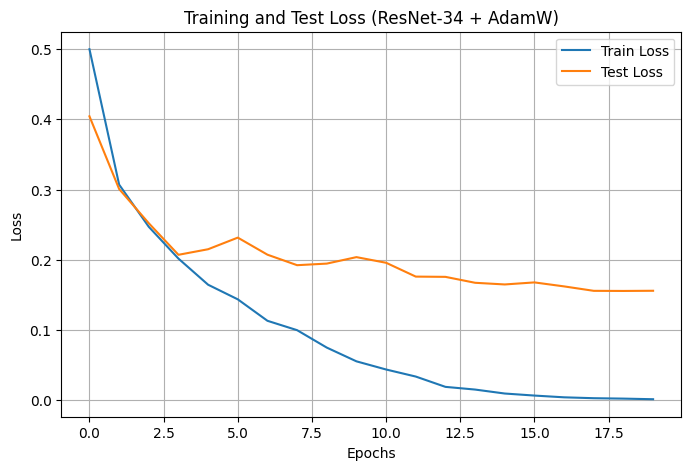

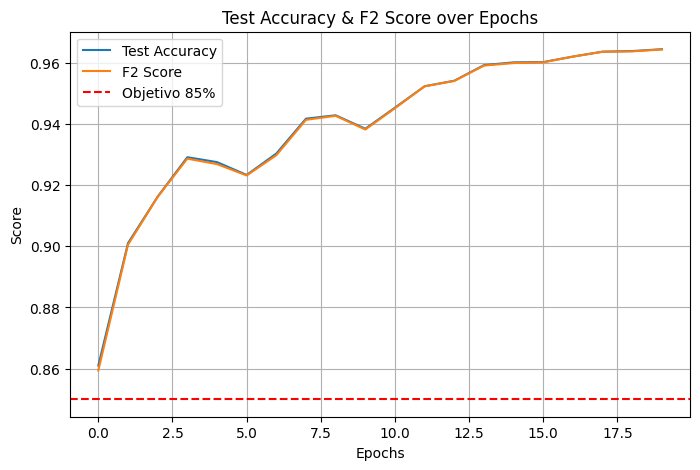

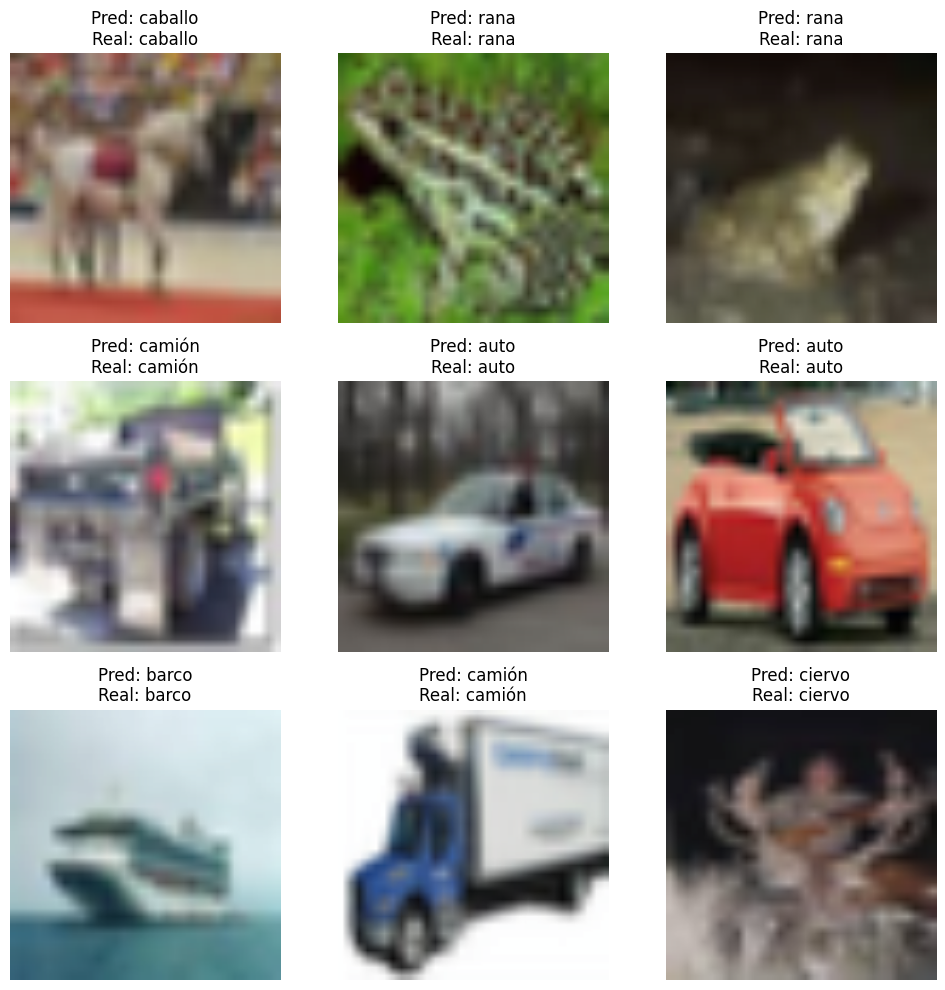

In [5]:
from pathlib import Path
from urllib.error import URLError

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms, models
from sklearn.metrics import precision_score, recall_score, fbeta_score

# Hiperparámetros optimizados
batch_size = 64
learning_rate = 0.0005
weight_decay = 1e-4
num_epochs = 20

# 1. Transformaciones separadas: Data Augmentation para Train, limpio para Test
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(224, padding=16),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class TransformSubset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

# Cargar CIFAR-10 en Colab
data_dir = Path('./data')
raw_dataset = datasets.CIFAR10(root=str(data_dir), train=True, download=True, transform=None)

# División 80/20 reproducible
generator = torch.Generator().manual_seed(42)
train_size = int(0.8 * len(raw_dataset))
test_size = len(raw_dataset) - train_size
train_subset, test_subset = random_split(raw_dataset, [train_size, test_size], generator=generator)

train_dataset = TransformSubset(train_subset, transform=train_transform)
test_dataset = TransformSubset(test_subset, transform=test_transform)

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

# 2. Transfer Learning con ResNet-34
model = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 10)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Entrenando en dispositivo: {device}")
model = model.to(device)

# 3. Función de pérdida, AdamW y CosineAnnealingLR
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)

train_losses, test_losses, test_accuracies, f2_scores = [], [], [], []

for epoch in range(num_epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    scheduler.step()
    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total
    train_losses.append(train_loss)

    model.eval()
    test_loss, correct, total = 0.0, 0, 0
    all_labels, all_predictions = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())

    avg_test_loss = test_loss / len(test_loader)
    test_accuracy = correct / total
    precision = precision_score(all_labels, all_predictions, average='macro')
    recall = recall_score(all_labels, all_predictions, average='macro')
    test_f2_score = fbeta_score(all_labels, all_predictions, average='macro', beta=2)

    test_losses.append(avg_test_loss)
    test_accuracies.append(test_accuracy)
    f2_scores.append(test_f2_score)

    current_lr = scheduler.get_last_lr()[0]
    print(
        f"Epoch [{epoch+1}/{num_epochs}] (LR: {current_lr:.6f}) | "
        f"Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.4f} | "
        f"Test Loss: {avg_test_loss:.4f}, Test Acc: {test_accuracy*100:.2f}%, "
        f"Precision: {precision:.4f}, Recall: {recall:.4f}, F2: {test_f2_score:.4f}"
    )

# Guardar pesos del modelo optimizado
torch.save(model.state_dict(), 'resnet34_cifar10_optimized.pth')

# Gráfica 1: Pérdidas
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Test Loss (ResNet-34 + AdamW)')
plt.grid(True)
plt.show()

# Gráfica 2: Accuracy y F2 Score
plt.figure(figsize=(8, 5))
plt.plot(test_accuracies, label='Test Accuracy')
plt.plot(f2_scores, label='F2 Score')
plt.axhline(y=0.85, color='r', linestyle='--', label='Objetivo 85%')
plt.xlabel('Epochs')
plt.ylabel('Score')
plt.legend()
plt.title('Test Accuracy & F2 Score over Epochs')
plt.grid(True)
plt.show()

# Gráfica 3: 9 imágenes clasificadas
classes = ('avión', 'auto', 'pájaro', 'gato', 'ciervo', 'perro', 'rana', 'caballo', 'barco', 'camión')
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

model.eval()
fig = plt.figure(figsize=(10, 10))
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        _, predicted = torch.max(outputs, 1)
        for j in range(9):
            ax = fig.add_subplot(3, 3, j + 1)
            img = images[j].cpu().numpy().transpose((1, 2, 0))
            img = np.clip(std * img + mean, 0, 1)
            ax.imshow(img)
            ax.set_title(f'Pred: {classes[predicted[j].item()]}\nReal: {classes[labels[j].item()]}')
            ax.axis('off')
        break
plt.tight_layout()
plt.show()